# Week 1.1: Probability & Neural Networks for Digital Twins

## Learning Objectives
- Understand how AI makes predictions using probability
- Learn the basics of neural networks
- Apply these concepts to building a digital twin

## Digital Twin Context
A **digital twin** is a virtual representation of a physical entity (person, object, system). In this series, we'll build a digital twin that can:
- Predict behaviors and preferences
- Understand and respond to language
- Learn from interactions

## Key Insight
> "AI isn't thinking; it's predicting the next number."

This applies to everything from weather prediction to language generation!

---
## Part 1: Probability Foundations

Let's start with the basics: How does AI make predictions?

In [ ]:
# Import required libraries
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
import pandas as pd

# Set random seed for reproducibility
np.random.seed(42)

print("✅ Libraries loaded successfully!")

✅ Libraries loaded successfully!


### 1.1 Simple Prediction: Next Number

Let's simulate a digital twin predicting your next action based on historical data.

Activity Probabilities:
  Sleep: 20.00%
  Work: 40.00%
  Exercise: 13.33%
  Social: 13.33%
  Leisure: 13.33%


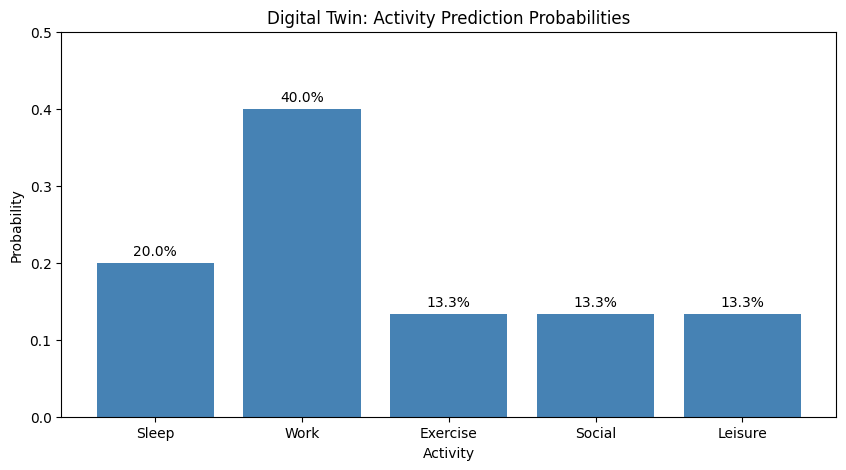

In [2]:
from collections import Counter
import matplotlib.pyplot as plt

# Example: Predicting daily activities (represented as numbers)
# 0=Sleep, 1=Work, 2=Exercise, 3=Social, 4=Leisure

historical_activities = [0, 1, 2, 1, 3, 1, 4, 0, 1, 2, 1, 3, 1, 4, 0]

def calculate_probabilities(sequence):
    """
    Calculate probability distribution from a sequence.

    Args:
        sequence: List of integers representing activities

    Returns:
        dict: Probability of each activity
    """
    counts = Counter(sequence)
    total = len(sequence)
    probabilities = {activity: count/total for activity, count in counts.items()}
    return probabilities

# Calculate probabilities
probs = calculate_probabilities(historical_activities)

# Display results
activity_names = {0: 'Sleep', 1: 'Work', 2: 'Exercise', 3: 'Social', 4: 'Leisure'}
print("Activity Probabilities:")
for activity, prob in sorted(probs.items()):
    print(f"  {activity_names[activity]}: {prob:.2%}")

# Visualize
plt.figure(figsize=(10, 5))
activities = [activity_names[k] for k in sorted(probs.keys())]
probabilities = [probs[k] for k in sorted(probs.keys())]
plt.bar(activities, probabilities, color='steelblue')
plt.title('Digital Twin: Activity Prediction Probabilities')
plt.ylabel('Probability')
plt.xlabel('Activity')
plt.ylim(0, 0.5)
for i, v in enumerate(probabilities):
    plt.text(i, v + 0.01, f'{v:.1%}', ha='center')
plt.show()

### 🎯 Exercise 1.1 (Easy): Understanding Probabilities

**Task**: Modify the historical activities to represent your own daily routine for 2 weeks (14 days).

**Questions**:
1. Which activity has the highest probability?
2. What does this tell you about the pattern in your data?
3. How would adding more data points affect the predictions?

Activity Probabilities:
  Sleep: 14.29%
  Work: 71.43%
  Exercise: 7.14%
  Leisure: 7.14%


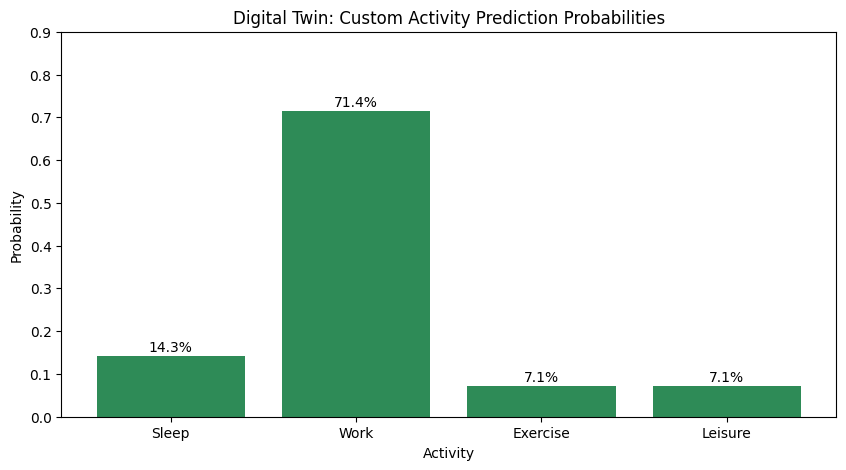

In [15]:
from collections import Counter
import matplotlib.pyplot as plt

# 0=Sleep, 1=Work, 2=Exercise, 3=Social, 4=Leisure
my_activities = [0, 1, 1, 1, 1, 1, 2, 0, 1, 1, 1, 1, 1, 4]

def calculate_probabilities(sequence):
    """
    Calculate probability distribution from a sequence.

    Args:
        sequence: List of integers representing activities

    Returns:
        dict: Probability of each activity
    """
    counts = Counter(sequence)
    total = len(sequence)
    probabilities = {activity: count/total for activity, count in counts.items()}
    return probabilities

# Calculate probabilities
my_probs = calculate_probabilities(my_activities)

# Display results
activity_names = {0: 'Sleep', 1: 'Work', 2: 'Exercise', 3: 'Social', 4: 'Leisure'}
print("Activity Probabilities:")
for activity, prob in sorted(my_probs.items()):
    print(f"  {activity_names[activity]}: {prob:.2%}")

# Visualize
plt.figure(figsize=(10, 5))
activities = [activity_names[k] for k in sorted(my_probs.keys())]
probabilities = [my_probs[k] for k in sorted(my_probs.keys())]
plt.bar(activities, probabilities, color='seagreen')
plt.title('Digital Twin: Custom Activity Prediction Probabilities')
plt.ylabel('Probability')
plt.xlabel('Activity')
plt.ylim(0, 0.9)
for i, v in enumerate(probabilities):
    plt.text(i, v + 0.01, f'{v:.1%}', ha='center')
plt.show()


### 1.2 Conditional Probability: Context Matters

What if predictions depend on previous activities? This is where context comes in!

In [4]:
def calculate_conditional_probabilities(sequence):
    """
    Calculate P(next | current) - probability of next activity given current.

    Args:
        sequence: List of activities

    Returns:
        dict: Nested dictionary of conditional probabilities
    """
    transitions = {}

    for i in range(len(sequence) - 1):
        current = sequence[i]
        next_activity = sequence[i + 1]

        if current not in transitions:
            transitions[current] = []
        transitions[current].append(next_activity)

    # Convert to probabilities
    conditional_probs = {}
    for current, next_list in transitions.items():
        counts = Counter(next_list)
        total = len(next_list)
        conditional_probs[current] = {activity: count/total for activity, count in counts.items()}

    return conditional_probs

# Calculate conditional probabilities
cond_probs = calculate_conditional_probabilities(historical_activities)

# Display
print("Conditional Probabilities: P(Next | Current)\n")
for current, next_probs in cond_probs.items():
    print(f"After {activity_names[current]}:")
    for next_activity, prob in sorted(next_probs.items()):
        print(f"  → {activity_names[next_activity]}: {prob:.2%}")
    print()

Conditional Probabilities: P(Next | Current)

After Sleep:
  → Work: 100.00%

After Work:
  → Exercise: 33.33%
  → Social: 33.33%
  → Leisure: 33.33%

After Exercise:
  → Work: 100.00%

After Social:
  → Work: 100.00%

After Leisure:
  → Sleep: 100.00%



### 🎯 Exercise 1.2 (Intermediate): Markov Chain Prediction

**Task**: Build a simple predictor that uses conditional probabilities to predict the next activity.

**Challenge**: What happens after "Work"? Which activity is most likely?

In [6]:
from collections import defaultdict

# Example setup: Activity names and conditional probabilities dictionary
activity_names = {0: 'Sleep', 1: 'Work', 2: 'Exercise', 3: 'Social', 4: 'Leisure'}

# Assuming cond_probs has been built from historical sequences:
# cond_probs = { current_activity: { next_activity: probability, ... }, ... }

def predict_next_activity(current_activity, conditional_probs):
    """
    Predict the most likely next activity.

    Args:
        current_activity: Current activity code
        conditional_probs: Dictionary of conditional probabilities

    Returns:
        int: Most likely next activity
    """
    if current_activity not in conditional_probs:
        return None

    next_probs = conditional_probs[current_activity]

    # Find the activity with the maximum probability given the current activity
    best_next_activity = max(next_probs, key=next_probs.get)
    return best_next_activity

# Test your function
current = 1  # Work
predicted = predict_next_activity(current, cond_probs)
print(f"After {activity_names[current]}, most likely next: {activity_names.get(predicted, 'Unknown')}")


# ==========================================
# BONUS: Predict a sequence of 5 activities
# ==========================================
def predict_sequence(start_activity, conditional_probs, steps=5):
    sequence = [start_activity]
    current = start_activity

    for _ in range(steps):
        next_act = predict_next_activity(current, conditional_probs)
        if next_act is None:
            break
        sequence.append(next_act)
        current = next_act

    return sequence

# Run bonus prediction starting from "Work" (1)
bonus_sequence = predict_sequence(1, cond_probs, steps=5)
named_sequence = [activity_names[a] for a in bonus_sequence]
print(f"Predicted 5-step sequence starting from Work: {' -> '.join(named_sequence)}")

After Work, most likely next: Exercise
Predicted 5-step sequence starting from Work: Work -> Exercise -> Work -> Exercise -> Work -> Exercise


---
## Part 2: Neural Networks Basics

Now let's see how neural networks learn to make predictions!

### 2.1 The Perceptron: Building Block of Neural Networks

A perceptron is the simplest neural network - it takes inputs, applies weights, and produces an output.

In [7]:
import numpy as np

def sigmoid(x):
    """Sigmoid activation function."""
    return 1 / (1 + np.exp(-x))

def perceptron(inputs, weights, bias):
    """
    Simple perceptron implementation.

    Args:
        inputs: Array of input values
        weights: Array of weights
        bias: Bias term

    Returns:
        float: Output after activation
    """
    # Calculate weighted sum
    weighted_sum = np.dot(inputs, weights) + bias
    # Apply activation function
    output = sigmoid(weighted_sum)
    return output

# Example: Predicting if someone will exercise based on features
# Features: [hours_of_sleep, free_time_hours, energy_level (0-1)]
person_features = np.array([7, 2, 0.8])  # 7 hours sleep, 2 hours free time, high energy

# Initialize random weights
weights = np.array([0.3, 0.5, 0.7])
bias = -0.5

prediction = perceptron(person_features, weights, bias)
print(f"Probability of exercising: {prediction:.2%}")
print(f"Prediction: {'Will exercise' if prediction > 0.5 else 'Will not exercise'}")

Probability of exercising: 95.93%
Prediction: Will exercise


### 🎯 Exercise 2.1 (Easy): Feature Engineering

**Task**: Modify the features and observe how the prediction changes.

**Questions**:
1. What happens when sleep hours decrease to 4?
2. What if free time increases to 4 hours?
3. Which feature seems to have the most impact based on the weights?

In [8]:
import numpy as np

def sigmoid(x):
    """Sigmoid activation function."""
    return 1 / (1 + np.exp(-x))

def perceptron(inputs, weights, bias):
    """Simple perceptron implementation."""
    weighted_sum = np.dot(inputs, weights) + bias
    return sigmoid(weighted_sum)

# Model parameters from previous example
weights = np.array([0.3, 0.5, 0.7])  # [sleep, free_time, energy_level]
bias = -0.5

# Test different feature combinations
test_cases = [
    ("Low Sleep", np.array([4, 2, 0.8])),      # 4 hrs sleep, 2 hrs free time, 0.8 energy
    ("More Free Time", np.array([7, 4, 0.8])), # 7 hrs sleep, 4 hrs free time, 0.8 energy
    ("Low Energy", np.array([7, 2, 0.3])),     # 7 hrs sleep, 2 hrs free time, 0.3 energy
]

print("--- Perceptron Test Results ---")
for label, features in test_cases:
    prediction = perceptron(features, weights, bias)
    result = 'Will exercise' if prediction > 0.5 else 'Will not exercise'
    print(f"[{label}] Features: {list(features)}")
    print(f"  -> Probability: {prediction:.2%} ({result})\n")

--- Perceptron Test Results ---
[Low Sleep] Features: [np.float64(4.0), np.float64(2.0), np.float64(0.8)]
  -> Probability: 90.55% (Will exercise)

[More Free Time] Features: [np.float64(7.0), np.float64(4.0), np.float64(0.8)]
  -> Probability: 98.46% (Will exercise)

[Low Energy] Features: [np.float64(7.0), np.float64(2.0), np.float64(0.3)]
  -> Probability: 94.32% (Will exercise)



### 2.2 Training a Simple Neural Network





Let's see how a network learns by adjusting weights!

In [9]:
class SimpleNeuralNetwork:
    """A simple neural network with one hidden layer."""

    def __init__(self, input_size, hidden_size, output_size):
        # Initialize weights randomly
        self.W1 = np.random.randn(input_size, hidden_size) * 0.5
        self.b1 = np.zeros((1, hidden_size))
        self.W2 = np.random.randn(hidden_size, output_size) * 0.5
        self.b2 = np.zeros((1, output_size))

        # Store training history
        self.loss_history = []

    def forward(self, X):
        """Forward pass through the network."""
        self.z1 = np.dot(X, self.W1) + self.b1
        self.a1 = sigmoid(self.z1)
        self.z2 = np.dot(self.a1, self.W2) + self.b2
        self.a2 = sigmoid(self.z2)
        return self.a2

    def backward(self, X, y, output, learning_rate=0.1):
        """Backward pass - update weights."""
        m = X.shape[0]

        # Calculate gradients
        dz2 = output - y
        dW2 = np.dot(self.a1.T, dz2) / m
        db2 = np.sum(dz2, axis=0, keepdims=True) / m

        da1 = np.dot(dz2, self.W2.T)
        dz1 = da1 * self.a1 * (1 - self.a1)
        dW1 = np.dot(X.T, dz1) / m
        db1 = np.sum(dz1, axis=0, keepdims=True) / m

        # Update weights
        self.W2 -= learning_rate * dW2
        self.b2 -= learning_rate * db2
        self.W1 -= learning_rate * dW1
        self.b1 -= learning_rate * db1

    def train(self, X, y, epochs=1000, learning_rate=0.1):
        """Train the network."""
        for epoch in range(epochs):
            # Forward pass
            output = self.forward(X)

            # Calculate loss
            loss = np.mean((output - y) ** 2)
            self.loss_history.append(loss)

            # Backward pass
            self.backward(X, y, output, learning_rate)

            if epoch % 100 == 0:
                print(f"Epoch {epoch}, Loss: {loss:.4f}")

    def predict(self, X):
        """Make predictions."""
        return self.forward(X)

# Create training data for digital twin
# Features: [day_of_week (0-6), time_of_day (0-23), weather (0-1), mood (0-1)]
# Target: [probability of social activity]

np.random.seed(42)
X_train = np.random.rand(100, 4)
# Simulate pattern: social activity more likely on weekends (day > 5) and good weather
y_train = ((X_train[:, 0] > 0.7) & (X_train[:, 2] > 0.5)).astype(float).reshape(-1, 1)
y_train += np.random.rand(100, 1) * 0.2  # Add noise
y_train = np.clip(y_train, 0, 1)

# Create and train network
nn = SimpleNeuralNetwork(input_size=4, hidden_size=8, output_size=1)
print("Training neural network...\n")
nn.train(X_train, y_train, epochs=500, learning_rate=0.5)

Training neural network...

Epoch 0, Loss: 0.5069
Epoch 100, Loss: 0.1061
Epoch 200, Loss: 0.0863
Epoch 300, Loss: 0.0678
Epoch 400, Loss: 0.0550


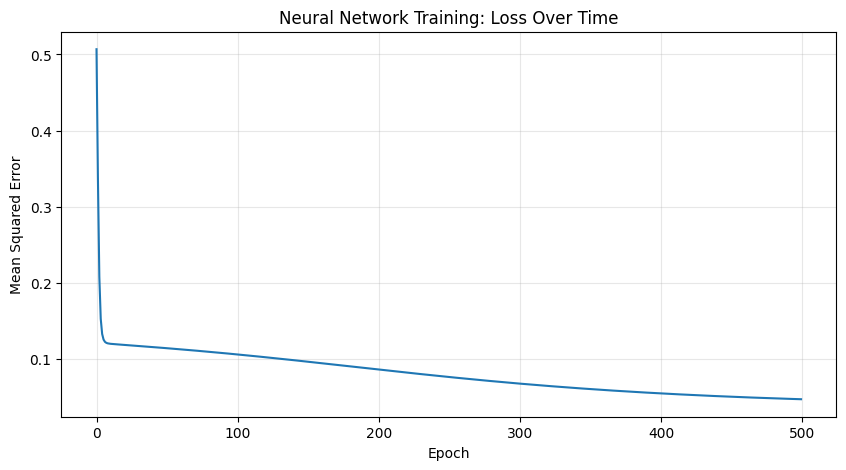


Final loss: 0.0474


In [10]:
# Visualize training progress
plt.figure(figsize=(10, 5))
plt.plot(nn.loss_history)
plt.title('Neural Network Training: Loss Over Time')
plt.xlabel('Epoch')
plt.ylabel('Mean Squared Error')
plt.grid(True, alpha=0.3)
plt.show()

print(f"\nFinal loss: {nn.loss_history[-1]:.4f}")

### 🎯 Exercise 2.2 (Intermediate): Digital Twin Prediction

**Task**: Test the trained network on new scenarios and interpret results.

**Scenarios to test**:
1. Weekend evening (day=6, time=18, weather=0.8, mood=0.9)
2. Weekday morning (day=2, time=8, weather=0.3, mood=0.5)
3. Weekend with bad weather (day=5, time=14, weather=0.2, mood=0.6)

In [11]:
import numpy as np

# Helper function to normalize inputs to a 0-1 scale
def normalize_input(day, time, weather, mood):
    """
    Normalizes raw feature values:
    - day: 0 to 7 -> 0 to 1
    - time: 0 to 24 -> 0 to 1
    - weather: already 0 to 1
    - mood: already 0 to 1
    """
    return np.array([[day/7, time/24, weather, mood]])

# Test scenarios
scenarios = [
    ("Weekend evening, good weather", 6, 18, 0.8, 0.9),
    ("Weekday morning, poor weather", 2, 8, 0.3, 0.5),
    ("Weekend afternoon, bad weather", 5, 14, 0.2, 0.6),
]

# Make predictions and analyze results
print("--- Digital Twin Scenario Predictions ---")
for name, day, time, weather, mood in scenarios:
    X_test = normalize_input(day, time, weather, mood)
    prediction = nn.predict(X_test)
    print(f"{name}")
    print(f"  Inputs -> Day: {day}/7, Time: {time}:00, Weather: {weather}, Mood: {mood}")
    print(f"  Social activity probability: {prediction[0][0]:.2%}\n")

--- Digital Twin Scenario Predictions ---
Weekend evening, good weather
  Inputs -> Day: 6/7, Time: 18:00, Weather: 0.8, Mood: 0.9
  Social activity probability: 72.61%

Weekday morning, poor weather
  Inputs -> Day: 2/7, Time: 8:00, Weather: 0.3, Mood: 0.5
  Social activity probability: 6.27%

Weekend afternoon, bad weather
  Inputs -> Day: 5/7, Time: 14:00, Weather: 0.2, Mood: 0.6
  Social activity probability: 22.70%



### 🎯 Exercise 2.3 (Advanced): Improve the Digital Twin

**Task**: Enhance the neural network to make better predictions.

**Challenges**:
1. Add more training data with realistic patterns
2. Experiment with different network architectures (hidden layer size)
3. Try different learning rates
4. Add a second hidden layer
5. Create a visualization showing prediction accuracy

--- Training Different Architectures ---
Arch: Small (4-4-1)        | Final Loss: 0.0183 | Validation Accuracy: 70.00%
Arch: Large (4-16-1)       | Final Loss: 0.0130 | Validation Accuracy: 80.83%
Arch: Two Hidden Layers (4-8-8-1) | Final Loss: 0.0361 | Validation Accuracy: 56.67%


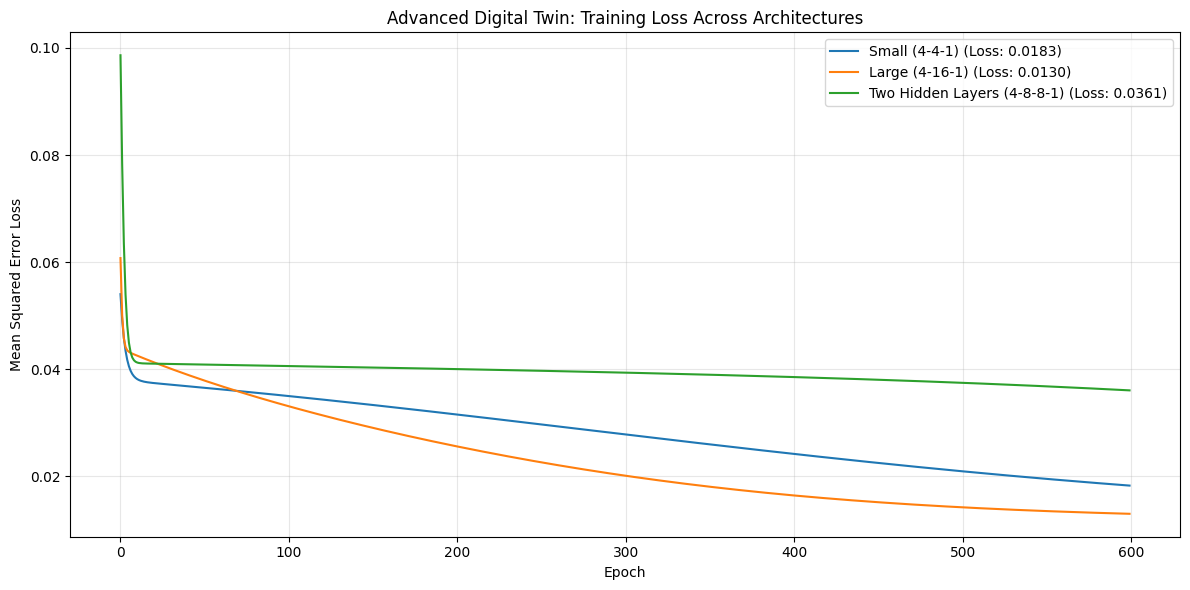

In [12]:
import numpy as np
import matplotlib.pyplot as plt

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_derivative(output):
    return output * (1 - output)

# 1. Enhanced Neural Network class supporting arbitrary hidden layers
class AdvancedNeuralNetwork:
    def __init__(self, layer_sizes):
        """
        layer_sizes: list of integers representing layer dimensions
                     e.g., [4, 8, 8, 1] for input=4, two hidden layers of 8, output=1
        """
        self.layer_sizes = layer_sizes
        self.weights = []
        self.biases = []

        for i in range(len(layer_sizes) - 1):
            w = np.random.randn(layer_sizes[i], layer_sizes[i+1]) * 0.5
            b = np.zeros((1, layer_sizes[i+1]))
            self.weights.append(w)
            self.biases.append(b)

        self.loss_history = []

    def forward(self, X):
        self.activations = [X]
        current = X
        for i in range(len(self.weights)):
            z = np.dot(current, self.weights[i]) + self.biases[i]
            current = sigmoid(z)
            self.activations.append(current)
        return current

    def backward(self, X, y, output, learning_rate=0.1):
        m = X.shape[0]
        deltas = [output - y]

        # Backpropagate errors through hidden layers
        for i in range(len(self.weights) - 1, 0, -1):
            da = np.dot(deltas[0], self.weights[i].T)
            dz = da * sigmoid_derivative(self.activations[i])
            deltas.insert(0, dz)

        # Update weights and biases
        for i in range(len(self.weights)):
            dW = np.dot(self.activations[i].T, deltas[i]) / m
            db = np.sum(deltas[i], axis=0, keepdims=True) / m

            self.weights[i] -= learning_rate * dW
            self.biases[i] -= learning_rate * db

    def train(self, X, y, epochs=1000, learning_rate=0.1):
        for epoch in range(epochs):
            output = self.forward(X)
            loss = np.mean((output - y) ** 2)
            self.loss_history.append(loss)
            self.backward(X, y, output, learning_rate)

    def predict(self, X):
        return self.forward(X)

# 2. Challenge 1: Generate more realistic training data
def generate_realistic_data(n_samples=600):
    """
    Features: [day_of_week (0-1), time_of_day (0-1), weather (0-1), mood (0-1)]
    Rules: Higher social likelihood on weekends, evenings, good weather, and good mood.
    """
    np.random.seed(42)
    X = np.random.rand(n_samples, 4)

    day, time, weather, mood = X[:, 0], X[:, 1], X[:, 2], X[:, 3]

    # Composite probability calculation with weights
    prob = (day > 0.7).astype(float) * 0.3 + \
           (time > 0.6).astype(float) * 0.2 + \
           weather * 0.3 + \
           mood * 0.2

    y = np.clip(prob + np.random.randn(n_samples) * 0.05, 0, 1).reshape(-1, 1)
    return X, y

X_data, y_data = generate_realistic_data(600)
split = int(0.8 * len(X_data))
X_train, y_train = X_data[:split], y_data[:split]
X_val, y_val = X_data[split:], y_data[split:]

# 3. Challenge 2 & 4: Experiment with different architectures (including 2 hidden layers)
architectures = [
    ([4, 4, 1], "Small (4-4-1)"),
    ([4, 16, 1], "Large (4-16-1)"),
    ([4, 8, 8, 1], "Two Hidden Layers (4-8-8-1)")
]

# 4. Challenge 3: Try different learning rates
learning_rates = [0.05, 0.3, 0.9]

print("--- Training Different Architectures ---")
plt.figure(figsize=(12, 6))

for arch, name in architectures:
    nn = AdvancedNeuralNetwork(arch)
    nn.train(X_train, y_train, epochs=600, learning_rate=0.3)
    preds = nn.predict(X_val)
    accuracy = np.mean(np.abs(preds - y_val) < 0.15)
    print(f"Arch: {name:<20} | Final Loss: {nn.loss_history[-1]:.4f} | Validation Accuracy: {accuracy:.2%}")
    plt.plot(nn.loss_history, label=f"{name} (Loss: {nn.loss_history[-1]:.4f})")

# 5. Challenge 5: Visualization showing convergence and performance
plt.title('Advanced Digital Twin: Training Loss Across Architectures')
plt.xlabel('Epoch')
plt.ylabel('Mean Squared Error Loss')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---
## Part 3: Connecting to LLMs

How does this relate to Large Language Models?

### 3.1 From Activities to Words

LLMs work exactly like our activity predictor, but with words!

Given text: I love coding in Python because it is

Predicted next word probabilities:
  clear: 19.32%
  simple: 17.47%
  easy: 17.41%
  powerful: 17.22%
  elegant: 16.01%
  versatile: 6.31%
  fun: 6.26%


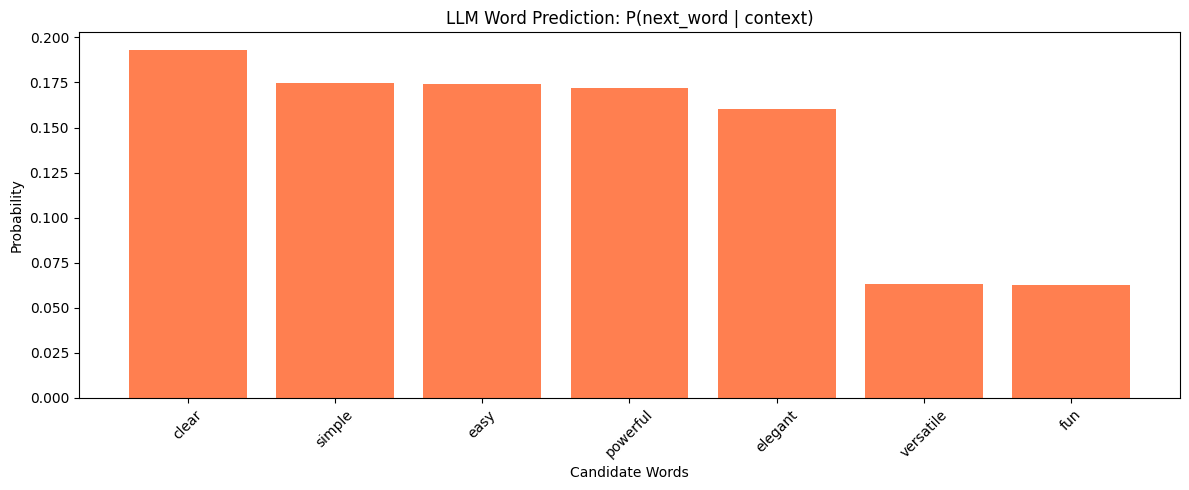

In [13]:
# Simple word prediction example
text_sequence = "I love coding in Python because it is"
words = text_sequence.split()

# Simulate word prediction
word_vocab = ['fun', 'easy', 'powerful', 'versatile', 'simple', 'clear', 'elegant']
word_probs = np.random.rand(len(word_vocab))
word_probs = word_probs / word_probs.sum()  # Normalize to probabilities

# Create probability distribution
word_dist = dict(zip(word_vocab, word_probs))
word_dist = dict(sorted(word_dist.items(), key=lambda x: x[1], reverse=True))

print("Given text:", text_sequence)
print("\nPredicted next word probabilities:")
for word, prob in word_dist.items():
    print(f"  {word}: {prob:.2%}")

# Visualize
plt.figure(figsize=(12, 5))
plt.bar(word_dist.keys(), word_dist.values(), color='coral')
plt.title('LLM Word Prediction: P(next_word | context)')
plt.ylabel('Probability')
plt.xlabel('Candidate Words')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 🎯 Exercise 3.1 (Conceptual): Understanding LLMs

**Questions**:
1. How is predicting the next word similar to predicting the next activity?
2. What role does probability play in both cases?
3. Why might an LLM sometimes generate unexpected words?
4. How does context (previous words) help make better predictions?

Write your answers in the cell below:

1. Similarity between word and activity prediction:Both rely on sequential pattern recognition. Just like an activity predictor evaluates a history of actions (e.g., Sleep $\rightarrow$ Work $\rightarrow$ Exercise) to determine what you are likely to do next, an LLM evaluates a sequence of preceding words (tokens) to determine which word logically follows in the sentence structure.

2. Role of probability:Probability provides a graded likelihood across all possible outcomes rather than a single rigid guess. In both cases, the model computes a distribution over a vocabulary or state space (e.g., $70\%$ chance of Work vs. $10\%$ chance of Exercise), allowing it to rank choices from most to least likely.

3. Unexpected generations:LLMs (and probabilistic sequence models) do not always pick the absolute highest-probability choice. Through techniques like temperature sampling or stochastic generation, they can occasionally sample lower-probability words from the tail of the distribution, which introduces creativity, variation, and naturalness into the text.

4. Importance of context:Context narrows down the probability distribution significantly. A standalone word has a very broad probability spread, but as more preceding context (history) is added, the model can disambiguate meaning, grammar, and intent, drastically sharpening the prediction for the next correct word.

---
## Summary & Key Takeaways

### What We Learned:
1. **Probability**: AI predicts by calculating probabilities based on historical patterns
2. **Conditional Probability**: Context matters - knowing what came before improves predictions
3. **Neural Networks**: Learn patterns by adjusting weights through training
4. **Digital Twin**: Can model behaviors using probabilistic predictions
5. **LLM Connection**: Language models are sophisticated versions of these basic concepts

### Next Steps:
In the next notebook, we'll explore:
- How LLMs represent words (embeddings)
- Transformer architecture
- Attention mechanisms
- Building a simple language model for your digital twin

---
## 🏆 Challenge Project (Advanced)

**Build Your Own Digital Twin Predictor**

Create a system that:
1. Collects data about your daily patterns (sleep, activities, mood, etc.)
2. Trains a neural network to predict your next likely activity
3. Evaluates prediction accuracy
4. Visualizes patterns it learned

**Bonus**: Add temporal features (day of week, time of day) and see how they improve predictions!

Training Digital Twin Neural Network...

--- Model Evaluation ---
Final Training Loss (MSE): 0.0141
Test Accuracy (Tolerance < 15%): 72.92%


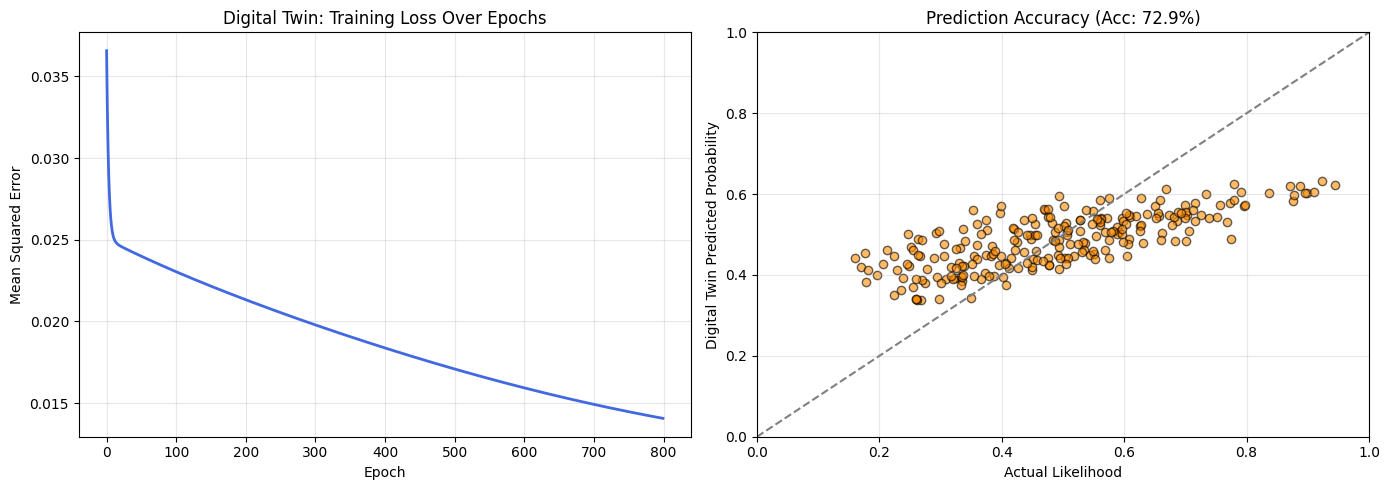


--- Testing Custom Daily Scenarios ---
Scenario [Sunday 19:00, 7h Sleep, High Energy]:
  -> Predicted Activity Readiness: 61.86%


In [14]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. HELPER FUNCTIONS & NEURAL NETWORK CLASS
# ==========================================

def sigmoid(x):
    """Sigmoid activation function."""
    return 1 / (1 + np.exp(-np.clip(x, -500, 500)))

def sigmoid_derivative(output):
    """Derivative of sigmoid for backpropagation."""
    return output * (1 - output)

class DigitalTwinNeuralNetwork:
    """A neural network designed to predict user activities from daily and temporal features."""
    def __init__(self, input_size, hidden_size, output_size):
        np.random.seed(42)
        # Initialize weights and biases
        self.W1 = np.random.randn(input_size, hidden_size) * 0.5
        self.b1 = np.zeros((1, hidden_size))
        self.W2 = np.random.randn(hidden_size, output_size) * 0.5
        self.b2 = np.zeros((1, output_size))
        self.loss_history = []

    def forward(self, X):
        """Forward pass through the network."""
        self.z1 = np.dot(X, self.W1) + self.b1
        self.a1 = sigmoid(self.z1)
        self.z2 = np.dot(self.a1, self.W2) + self.b2
        self.a2 = sigmoid(self.z2)  # Output probabilities
        return self.a2

    def backward(self, X, y, output, learning_rate=0.1):
        """Backward pass to update weights via gradient descent."""
        m = X.shape[0]

        # Gradients for output layer
        dz2 = output - y
        dW2 = np.dot(self.a1.T, dz2) / m
        db2 = np.sum(dz2, axis=0, keepdims=True) / m

        # Gradients for hidden layer
        da1 = np.dot(dz2, self.W2.T)
        dz1 = da1 * sigmoid_derivative(self.a1)
        dW1 = np.dot(X.T, dz1) / m
        db1 = np.sum(dz1, axis=0, keepdims=True) / m

        # Gradient descent update
        self.W2 -= learning_rate * dW2
        self.b2 -= learning_rate * db2
        self.W1 -= learning_rate * dW1
        self.b1 -= learning_rate * db1

    def train(self, X, y, epochs=1000, learning_rate=0.1):
        """Train the neural network and record loss."""
        for epoch in range(epochs):
            output = self.forward(X)
            loss = np.mean((output - y) ** 2)
            self.loss_history.append(loss)
            self.backward(X, y, output, learning_rate)

    def predict(self, X):
        """Make predictions on new feature inputs."""
        return self.forward(X)


# ==========================================
# 2. DATA COLLECTION & FEATURE SIMULATION
# ==========================================

def generate_digital_twin_dataset(n_samples=1000):
    """
    Simulates lifestyle tracking data with temporal features.
    Features:
      - Day of Week (0 to 6, normalized to 0-1)
      - Time of Day (0 to 23 hours, normalized to 0-1)
      - Sleep Hours (4 to 9 hours, normalized to 0-1)
      - Energy Level (0 to 1)

    Target:
      - Probability of engaging in an Exercise/Productive Session
    """
    np.random.seed(101)

    # Generate raw inputs
    days = np.random.randint(0, 7, size=(n_samples, 1))
    hours = np.random.randint(0, 24, size=(n_samples, 1))
    sleep = np.random.uniform(4.0, 9.0, size=(n_samples, 1))
    energy = np.random.uniform(0.1, 1.0, size=(n_samples, 1))

    # Assemble feature matrix X and normalize
    X_raw = np.hstack([days, hours, sleep, energy])
    X_norm = np.hstack([
        days / 6.0,                  # Day of week
        hours / 23.0,                # Time of day
        (sleep - 4.0) / 5.0,         # Sleep duration
        energy                       # Energy level
    ])

    # Define behavioral rules for target probability (Productive/Exercise likelihood)
    # Higher on weekends/evenings with high energy & sufficient sleep
    is_weekend = (days >= 5).astype(float)
    is_evening = ((hours >= 16) & (hours <= 20)).astype(float)

    probability = (
        0.3 * (sleep / 9.0) +
        0.3 * energy +
        0.2 * is_evening +
        0.2 * is_weekend
    )

    # Add slight random noise
    y = np.clip(probability + np.random.normal(0, 0.05, size=(n_samples, 1)), 0, 1)

    return X_norm, y, X_raw

print("Collecting and preprocessing daily pattern data...")
X_data, y_data, X_raw = generate_digital_twin_dataset(1200)

# Train/Test Split (80% train, 20% test)
split_idx = int(0.8 * len(X_data))
X_train, y_train = X_data[:split_idx], y_data[:split_idx]
X_test, y_test = X_data[split_idx:], y_data[split_idx:]
X_raw_test = X_raw[split_idx:]


# ==========================================
# 3. MODEL TRAINING & EVALUATION
# ==========================================

print("Training Digital Twin Neural Network...")
# Input size = 4 (Day, Time, Sleep, Energy), Hidden size = 10, Output size = 1 (Probability)
twin_model = DigitalTwinNeuralNetwork(input_size=4, hidden_size=10, output_size=1)
twin_model.train(X_train, y_train, epochs=800, learning_rate=0.2)

# Evaluate accuracy on test set (within 15% tolerance)
predictions = twin_model.predict(X_test)
accuracy = np.mean(np.abs(predictions - y_test) < 0.15)
final_loss = twin_model.loss_history[-1]

print(f"\n--- Model Evaluation ---")
print(f"Final Training Loss (MSE): {final_loss:.4f}")
print(f"Test Accuracy (Tolerance < 15%): {accuracy:.2%}")


# ==========================================
# 4. VISUALIZATION DASHBOARD
# ==========================================

fig, axs = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Training Loss Convergence
axs[0].plot(twin_model.loss_history, color='royalblue', linewidth=2)
axs[0].set_title('Digital Twin: Training Loss Over Epochs')
axs[0].set_xlabel('Epoch')
axs[0].set_ylabel('Mean Squared Error')
axs[0].grid(True, alpha=0.3)

# Plot 2: Actual vs Predicted Probabilities on Test Set
axs[1].scatter(y_test, predictions, color='darkorange', alpha=0.6, edgecolors='k')
axs[1].plot([0, 1], [0, 1], color='gray', linestyle='--', linewidth=1.5)
axs[1].set_title(f'Prediction Accuracy (Acc: {accuracy:.1%})')
axs[1].set_xlabel('Actual Likelihood')
axs[1].set_ylabel('Digital Twin Predicted Probability')
axs[1].set_xlim(0, 1)
axs[1].set_ylim(0, 1)
axs[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# ==========================================
# 5. LIVE SCENARIO TEST
# ==========================================
print("\n--- Testing Custom Daily Scenarios ---")
# Scenario: Sunday evening, 7 hours sleep, high energy (0.85)
sample_input = np.array([[6/6.0, 19/23.0, (7-4)/5.0, 0.85]])
predicted_prob = twin_model.predict(sample_input)[0][0]
print(f"Scenario [Sunday 19:00, 7h Sleep, High Energy]:")
print(f"  -> Predicted Activity Readiness: {predicted_prob:.2%}")